# Movie Recommendation System

This notebook compares three approaches using the MovieLens ratings data:

1. **Baseline model** — predicts the average rating from the training set for every user–movie pair.
2. **SVD** — a collaborative-filtering model from the `scikit-surprise` library.
3. **Neural Collaborative Filtering (NCF)** — a PyTorch neural network that learns user and movie embeddings.

We use the same train/test split for all three models, then compare **MAE** and **RMSE**. Lower values indicate more accurate rating predictions.


## 1. Imports and setup

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

PROCESSED_DIR = Path("../data/processed")

PyTorch: 2.9.1+cpu
Device: cpu


## 2. Load and inspect the processed dataset

In [2]:
df = pd.read_csv(PROCESSED_DIR / "final_df.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (101696, 31)
Columns: ['userId', 'movieId', 'rating', 'timestamp', 'year', 'month', 'user_avg', 'user_count', 'title', 'genres', 'genre_Action', 'genre_Adventure', 'genre_Animation', 'genre_Children', 'genre_Comedy', 'genre_Crime', 'genre_Documentary', 'genre_Drama', 'genre_Fantasy', 'genre_Film-Noir', 'genre_Horror', 'genre_IMAX', 'genre_Musical', 'genre_Mystery', 'genre_Romance', 'genre_Sci-Fi', 'genre_Thriller', 'genre_War', 'genre_Western', 'avg_rating', 'num_ratings']


,userId,movieId,rating,timestamp,year,month,user_avg,user_count,title,genres,...,genre_IMAX,genre_Musical,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Thriller,genre_War,genre_Western,avg_rating,num_ratings
0,1,16,4.0,2008-08-05 00:56:33,2008,8,3.638393,112,Casino (1995),Crime|Drama,...,0,0,0,0,0,0,0,0,3.785714,84
1,1,24,1.5,2008-08-05 00:23:27,2008,8,3.638393,112,Powder (1995),Drama|Sci-Fi,...,0,0,0,0,1,0,0,0,2.894737,38
2,1,32,4.0,2008-08-05 00:30:46,2008,8,3.638393,112,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller,...,0,0,1,0,1,1,0,0,3.939614,207
3,1,47,4.0,2008-08-05 00:35:56,2008,8,3.638393,112,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,...,0,0,1,0,0,1,0,0,4.130102,196
4,1,50,4.0,2008-08-05 00:35:23,2008,8,3.638393,112,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,...,0,0,1,0,0,1,0,0,4.328947,228


## 3. Select ratings and split the data

In [ ]:
ratings = df[["userId", "movieId", "rating"]].copy()

print("Ratings shape:", ratings.shape)
print("Duplicate user-movie pairs:", ratings.duplicated(["userId", "movieId"]).sum())

train_data, test_data = train_test_split( 
    ratings,
    test_size=0.2,
    random_state=SEED
)

train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

Ratings shape: (101696, 3)
Duplicate user-movie pairs: 0
Training data: (81356, 3)
Testing data: (20340, 3)


## 4. Model 1 — Baseline

The baseline predicts the **mean rating in the training set** for every test example. It is a simple reference point: more advanced models should ideally outperform it.

In [4]:
baseline_prediction = train_data["rating"].mean()
y_test = test_data["rating"].to_numpy()

baseline_predictions = np.full(
    shape=len(test_data),
    fill_value=baseline_prediction,
    dtype=float
)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))

print(f"Mean training rating: {baseline_prediction:.4f}")
print(f"Baseline MAE: {baseline_mae:.4f}")
print(f"Baseline RMSE: {baseline_rmse:.4f}")

Mean training rating: 3.5338
Baseline MAE: 0.8353
Baseline RMSE: 1.0391


## 5. Model 2 — SVD with Surprise

SVD learns lower-dimensional representations of users and movies from their observed ratings. This implementation uses the `scikit-surprise` library.

If the import fails, install the package in a separate notebook cell with `%pip install scikit-surprise`, then restart the kernel if needed.

In [5]:
from surprise import Dataset, Reader, SVD

In [6]:
reader = Reader(rating_scale=(0.5, 5))

train_dataset = Dataset.load_from_df(
    train_data[["userId", "movieId", "rating"]],
    reader
)
trainset = train_dataset.build_full_trainset()

print("Users in SVD training set:", trainset.n_users)
print("Movies in SVD training set:", trainset.n_items)
print("Ratings used for training:", trainset.n_ratings)

Users in SVD training set: 668
Movies in SVD training set: 6623
Ratings used for training: 81356


In [7]:
svd_model = SVD(
    n_factors=100,
    n_epochs=20,
    random_state=SEED
)

svd_model.fit(trainset)
print("SVD training completed.")

SVD training completed.


In [8]:
svd_predictions = []

for row in test_data.itertuples(index=False):
    prediction = svd_model.predict(
        uid=row.userId,
        iid=row.movieId
    )
    svd_predictions.append(prediction.est)

svd_predictions = np.array(svd_predictions)

svd_mae = mean_absolute_error(y_test, svd_predictions)
svd_rmse = np.sqrt(mean_squared_error(y_test, svd_predictions))

print(f"SVD MAE: {svd_mae:.4f}")
print(f"SVD RMSE: {svd_rmse:.4f}")

SVD MAE: 0.6676
SVD RMSE: 0.8660


## 6. Model 3 — Neural Collaborative Filtering (PyTorch)

NCF learns an embedding vector for each user and each movie. It joins the two vectors and passes them through a small neural network to predict the rating. User and movie bias terms help the model account for users who tend to rate high or low and movies that tend to receive high or low ratings.

Only observed ratings are used for training; missing user–movie ratings are not filled with zeros.

### 6.1 Prepare user and movie indices

In [9]:
# Build mappings from the training set only.
user_ids = train_data["userId"].unique()
movie_ids = train_data["movieId"].unique()

user_to_index = {user_id: index for index, user_id in enumerate(user_ids)}
movie_to_index = {movie_id: index for index, movie_id in enumerate(movie_ids)}

n_users = len(user_to_index)
n_movies = len(movie_to_index)

ncf_train = train_data[["userId", "movieId", "rating"]].copy()
ncf_test = test_data[["userId", "movieId", "rating"]].copy()

ncf_train["user_index"] = ncf_train["userId"].map(user_to_index).astype("int64")
ncf_train["movie_index"] = ncf_train["movieId"].map(movie_to_index).astype("int64")

ncf_test["user_index"] = ncf_test["userId"].map(user_to_index)
ncf_test["movie_index"] = ncf_test["movieId"].map(movie_to_index)

# Test rows containing an unseen user or movie cannot use a learned embedding.
known_test_mask = ncf_test["user_index"].notna() & ncf_test["movie_index"].notna()
ncf_test_known = ncf_test.loc[known_test_mask].copy()
ncf_test_known["user_index"] = ncf_test_known["user_index"].astype("int64")
ncf_test_known["movie_index"] = ncf_test_known["movie_index"].astype("int64")

print("Users:", n_users)
print("Movies:", n_movies)
print("Known test rows:", len(ncf_test_known))
print("Test rows with unseen user/movie:", int((~known_test_mask).sum()))

Users: 668
Movies: 6623
Known test rows: 20208
Test rows with unseen user/movie: 132


### 6.2 Create a PyTorch dataset and data loader

In [10]:
class MovieRatingsDataset(Dataset):
    def __init__(self, frame):
        self.users = torch.tensor(frame["user_index"].to_numpy(), dtype=torch.long)
        self.movies = torch.tensor(frame["movie_index"].to_numpy(), dtype=torch.long)
        self.ratings = torch.tensor(
            frame["rating"].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.ratings)

    def __getitem__(self, index):
        return self.users[index], self.movies[index], self.ratings[index]


BATCH_SIZE = 1024

train_loader = DataLoader(
    MovieRatingsDataset(ncf_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)

### 6.3 Define the neural network

In [11]:
class NeuralCollaborativeFiltering(nn.Module):
    def __init__(self, n_users, n_movies, embedding_dim=32):
        super().__init__()

        self.user_embedding = nn.Embedding(n_users, embedding_dim)
        self.movie_embedding = nn.Embedding(n_movies, embedding_dim)

        self.user_bias = nn.Embedding(n_users, 1)
        self.movie_bias = nn.Embedding(n_movies, 1)

        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(32, 1)
        )

        self.global_mean = nn.Parameter(torch.tensor(3.5, dtype=torch.float32))

        nn.init.normal_(self.user_embedding.weight, mean=0.0, std=0.05)
        nn.init.normal_(self.movie_embedding.weight, mean=0.0, std=0.05)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, user_indices, movie_indices):
        user_vector = self.user_embedding(user_indices)
        movie_vector = self.movie_embedding(movie_indices)

        combined = torch.cat([user_vector, movie_vector], dim=1)
        neural_score = self.mlp(combined).squeeze(1)

        user_bias = self.user_bias(user_indices).squeeze(1)
        movie_bias = self.movie_bias(movie_indices).squeeze(1)

        predicted_rating = (
            self.global_mean + user_bias + movie_bias + neural_score
        )

        # MovieLens ratings range from 0.5 to 5.
        return torch.clamp(predicted_rating, min=0.5, max=5.0)


ncf_model = NeuralCollaborativeFiltering(
    n_users=n_users,
    n_movies=n_movies,
    embedding_dim=32
).to(device)

print(ncf_model)

NeuralCollaborativeFiltering(
  (user_embedding): Embedding(668, 32)
  (movie_embedding): Embedding(6623, 32)
  (user_bias): Embedding(668, 1)
  (movie_bias): Embedding(6623, 1)
  (mlp): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


### 6.4 Train the model

In [12]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(
    ncf_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

EPOCHS = 15
ncf_training_losses = []

for epoch in range(EPOCHS):
    ncf_model.train()
    total_loss = 0.0
    total_rows = 0

    for user_batch, movie_batch, rating_batch in train_loader:
        user_batch = user_batch.to(device)
        movie_batch = movie_batch.to(device)
        rating_batch = rating_batch.to(device)

        optimizer.zero_grad()
        predictions = ncf_model(user_batch, movie_batch)
        loss = loss_function(predictions, rating_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(rating_batch)
        total_rows += len(rating_batch)

    epoch_mse = total_loss / total_rows
    ncf_training_losses.append(epoch_mse)
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} - training MSE: {epoch_mse:.4f}")

Epoch 01/15 - training MSE: 0.9646
Epoch 02/15 - training MSE: 0.7334
Epoch 03/15 - training MSE: 0.6771
Epoch 04/15 - training MSE: 0.6527
Epoch 05/15 - training MSE: 0.6375
Epoch 06/15 - training MSE: 0.6262
Epoch 07/15 - training MSE: 0.6147
Epoch 08/15 - training MSE: 0.6043
Epoch 09/15 - training MSE: 0.5969
Epoch 10/15 - training MSE: 0.5886
Epoch 11/15 - training MSE: 0.5797
Epoch 12/15 - training MSE: 0.5737
Epoch 13/15 - training MSE: 0.5648
Epoch 14/15 - training MSE: 0.5571
Epoch 15/15 - training MSE: 0.5489


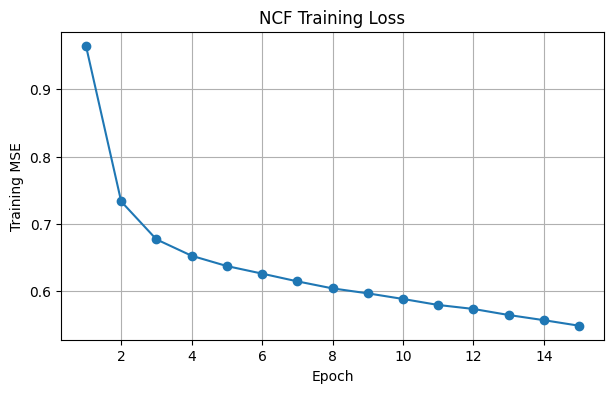

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), ncf_training_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("NCF Training Loss")
plt.grid(True)
plt.show()

### 6.5 Evaluate NCF on the test set

In [14]:
# Use the training mean as a fallback for any test row with an unseen ID.
ncf_predictions = np.full(
    len(ncf_test),
    fill_value=train_data["rating"].mean(),
    dtype=np.float32
)

ncf_model.eval()
with torch.no_grad():
    if len(ncf_test_known) > 0:
        test_users_tensor = torch.tensor(
            ncf_test_known["user_index"].to_numpy(),
            dtype=torch.long,
            device=device
        )
        test_movies_tensor = torch.tensor(
            ncf_test_known["movie_index"].to_numpy(),
            dtype=torch.long,
            device=device
        )

        known_predictions = ncf_model(
            test_users_tensor,
            test_movies_tensor
        ).cpu().numpy()

        ncf_predictions[np.flatnonzero(known_test_mask.to_numpy())] = known_predictions

ncf_mae = mean_absolute_error(y_test, ncf_predictions)
ncf_rmse = np.sqrt(mean_squared_error(y_test, ncf_predictions))

print(f"NCF MAE: {ncf_mae:.4f}")
print(f"NCF RMSE: {ncf_rmse:.4f}")

NCF MAE: 0.6654
NCF RMSE: 0.8718


## 7. Compare all models

In [15]:
results = pd.DataFrame({
    "Model": ["Baseline (mean)", "SVD (Surprise)", "Neural Collaborative Filtering"],
    "MAE": [baseline_mae, svd_mae, ncf_mae],
    "RMSE": [baseline_rmse, svd_rmse, ncf_rmse]
}).sort_values("RMSE").reset_index(drop=True)

display(results.round(4))

,Model,MAE,RMSE
0,SVD (Surprise),0.6676,0.8660
1,Neural Collaborative Filtering,0.6654,0.8718
2,Baseline (mean),0.8353,1.0391


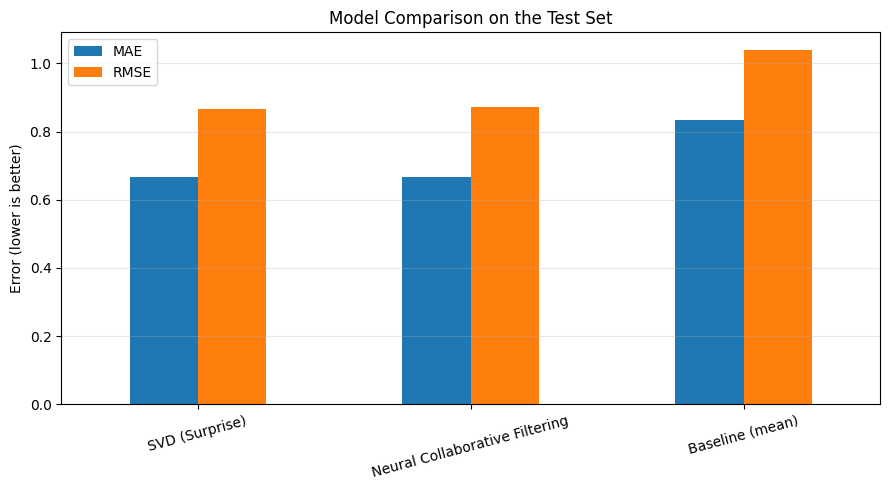

In [16]:
ax = results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5),
    rot=15
)
ax.set_title("Model Comparison on the Test Set")
ax.set_ylabel("Error (lower is better)")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Generate movie recommendations

The function below predicts ratings for movies the selected user has not rated in the original dataset and returns the highest predicted ratings. It can only recommend movies that appeared in the training data, because the model has not learned embeddings for movies it never saw during training.

In [17]:
# Build movie metadata for readable recommendations.
metadata_columns = ["movieId"]
if "title" in df.columns:
    metadata_columns.append("title")
if "genres" in df.columns:
    metadata_columns.append("genres")

movie_metadata = df[metadata_columns].drop_duplicates("movieId").copy()

# Exclude every movie the user rated in the original data, not only training data.
all_user_movie_pairs = ratings[["userId", "movieId"]].drop_duplicates()


def recommend_movies(user_id, n_recommendations=10):
    """Recommend unrated movies with the highest NCF-predicted ratings."""
    if user_id not in user_to_index:
        raise ValueError(
            f"User {user_id} was not present in training data; no user embedding exists."
        )

    already_rated = set(
        all_user_movie_pairs.loc[
            all_user_movie_pairs["userId"] == user_id, "movieId"
        ]
    )

    candidate_movie_ids = [
        movie_id for movie_id in movie_to_index
        if movie_id not in already_rated
    ]

    if not candidate_movie_ids:
        return pd.DataFrame(columns=["movieId", "predicted_rating"])

    user_index = user_to_index[user_id]
    user_indices = torch.full(
        (len(candidate_movie_ids),),
        fill_value=user_index,
        dtype=torch.long,
        device=device
    )
    movie_indices = torch.tensor(
        [movie_to_index[movie_id] for movie_id in candidate_movie_ids],
        dtype=torch.long,
        device=device
    )

    ncf_model.eval()
    with torch.no_grad():
        predicted_ratings = ncf_model(
            user_indices, movie_indices
        ).cpu().numpy()

    recommendations = pd.DataFrame({
        "movieId": candidate_movie_ids,
        "predicted_rating": predicted_ratings
    })

    recommendations = recommendations.sort_values(
        "predicted_rating", ascending=False
    )
    recommendations = recommendations.merge(
        movie_metadata, on="movieId", how="left"
    )

    return recommendations.head(n_recommendations).reset_index(drop=True)


# Example: choose a user that exists in the training data.
example_user_id = int(train_data["userId"].iloc[0])
print(f"Top recommendations for user {example_user_id}:")
display(recommend_movies(example_user_id, n_recommendations=10))

Top recommendations for user 170:


,movieId,predicted_rating,title,genres
0,80969,4.650053,Never Let Me Go (2010),Drama|Romance|Sci-Fi
1,77658,4.578223,Cosmos (1980),Documentary
2,105355,4.549620,Blue Is the Warmest Color (La vie d'Adèle) (2013),Drama|Romance
3,1809,4.503630,Fireworks (Hana-bi) (1997),Crime|Drama
4,7566,4.485165,28 Up (1985),Documentary
5,93040,4.456887,"Civil War, The (1990)",Documentary|War
6,86377,4.454710,Louis C.K.: Shameless (2007),Comedy
7,95873,4.453235,Ruby Sparks (2012),Comedy|Fantasy|Romance
8,8477,4.451603,"Pier, The (Jetée, La) (1962)",Romance|Sci-Fi
9,31437,4.422463,Nobody Knows (Dare mo shiranai) (2004),Drama
